<a href="https://colab.research.google.com/github/sapkale12345/Short_Term_Electricity_Consumption_Forecasting-Time_Series-/blob/main/Short_Term_Electricity_Consumption_Forecasting(Time_Series)2.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.set_option("display.max_columns", None)
pd.set_option("display.max_rows", 10)

# Data Loading & Initial Data Understanding

In [ ]:
data = pd.read_csv("/content/drive/MyDrive/Colab Notebooks/Electric Power Consumption/Data/Electricity consumption Dataset",usecols=[
        'Datetime',
        'PowerConsumption_Zone1',
        'PowerConsumption_Zone2',
        'PowerConsumption_Zone3'
    ]
)

In [ ]:
data.head()

,Datetime,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
0,1/1/2017 0:00,34055.69620,16128.87538,20240.96386
1,1/1/2017 0:10,29814.68354,19375.07599,20131.08434
2,1/1/2017 0:20,29128.10127,19006.68693,19668.43373
3,1/1/2017 0:30,28228.86076,18361.09422,18899.27711
4,1/1/2017 0:40,27335.69620,17872.34043,18442.40964


In [ ]:
data.shape

(52416, 4)

In [ ]:
52416+(24*6)

52560

In [ ]:
data.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 52416 entries, 0 to 52415
Data columns (total 4 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   Datetime                52416 non-null  object 
 1   PowerConsumption_Zone1  52416 non-null  float64
 2   PowerConsumption_Zone2  52416 non-null  float64
 3   PowerConsumption_Zone3  52416 non-null  float64
dtypes: float64(3), object(1)
memory usage: 1.6+ MB


Statistical Summary

In [ ]:
data.describe()

,PowerConsumption_Zone1,PowerConsumption_Zone2,PowerConsumption_Zone3
count,52416.000000,52416.000000,52416.000000
mean,32344.970564,21042.509082,17835.406218
std,7130.562564,5201.465892,6622.165099
min,13895.696200,8560.081466,5935.174070
25%,26310.668692,16980.766032,13129.326630
50%,32265.920340,20823.168405,16415.117470
75%,37309.018185,24713.717520,21624.100420
max,52204.395120,37408.860760,47598.326360


In [ ]:
data.columns

Index(['Datetime', 'PowerConsumption_Zone1', 'PowerConsumption_Zone2',
       'PowerConsumption_Zone3'],
      dtype='object')

In [ ]:
print(6*24*364)

52416


Time Range

In [ ]:
data["Datetime"] = pd.to_datetime(data["Datetime"])

print("Start Date :", data["Datetime"].min())
print("End Date   :", data["Datetime"].max())

data["Datetime"].diff().value_counts().head(10)

Start Date : 2017-01-01 00:00:00
End Date   : 2017-12-30 23:50:00


,count
Datetime,
0 days 00:10:00,52415


# Data Preparation

Data Cleaning

In [ ]:
# Duplicate Datetime
duplicate_time = data["Datetime"].duplicated().sum()

print("Duplicate DateTime :", duplicate_time)

Duplicate DateTime : 0


Data Transformation

In [ ]:
data = data.rename(columns={
    "PowerConsumption_Zone1": "Zone1",
    "PowerConsumption_Zone2": "Zone2",
    "PowerConsumption_Zone3": "Zone3"
})

data.columns

Index(['Datetime', 'Zone1', 'Zone2', 'Zone3'], dtype='object')

In [ ]:
# Create target variable
data["Total_Consumption"] = (
    data["Zone1"] +
    data["Zone2"] +
    data["Zone3"]
)

# Display first five rows
data[["Zone1", "Zone2", "Zone3", "Total_Consumption"]].head()

,Zone1,Zone2,Zone3,Total_Consumption
0,34055.69620,16128.87538,20240.96386,70425.53544
1,29814.68354,19375.07599,20131.08434,69320.84387
2,29128.10127,19006.68693,19668.43373,67803.22193
3,28228.86076,18361.09422,18899.27711,65489.23209
4,27335.69620,17872.34043,18442.40964,63650.44627


The electricity consumption values from the three distribution zones were aggregated to create a new variable named Total_Consumption. This variable represents the overall electricity demand of the city and serves as the target variable for forecasting. Aggregating the three zones simplifies the forecasting problem while preserving the overall demand pattern.

Sort Data and Set Datetime as Index

In [ ]:
# Sort by datetime
data = data.sort_values(by="Datetime")

# Set Datetime as index
data.set_index("Datetime", inplace=True)

# Verify
print(data.index)

# Display first five rows
data.head()

DatetimeIndex(['2017-01-01 00:00:00', '2017-01-01 00:10:00',
               '2017-01-01 00:20:00', '2017-01-01 00:30:00',
               '2017-01-01 00:40:00', '2017-01-01 00:50:00',
               '2017-01-01 01:00:00', '2017-01-01 01:10:00',
               '2017-01-01 01:20:00', '2017-01-01 01:30:00',
               ...
               '2017-12-30 22:20:00', '2017-12-30 22:30:00',
               '2017-12-30 22:40:00', '2017-12-30 22:50:00',
               '2017-12-30 23:00:00', '2017-12-30 23:10:00',
               '2017-12-30 23:20:00', '2017-12-30 23:30:00',
               '2017-12-30 23:40:00', '2017-12-30 23:50:00'],
              dtype='datetime64[ns]', name='Datetime', length=52416, freq=None)


,Temperature,Humidity,Wind_Speed,General_Diffuse_Flows,Diffuse_Flows,Zone1,Zone2,Zone3,Total_Consumption
Datetime,,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,70425.53544
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,69320.84387
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,67803.22193
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,65489.23209
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,63650.44627


The Datetime column was converted to the datetime64[ns] data type and set as the DataFrame index. This preserves the chronological order of observations and enables efficient time-based operations such as resampling, rolling statistics, seasonal decomposition, and forecasting.

Basic Feature Engineering

In [ ]:
data["Hour"] = data.index.hour
data["Day"] = data.index.day
data["Month"] = data.index.month
data["Weekday"] = data.index.day_name()
data["Weekend"] = data["Weekday"].isin(["Saturday", "Sunday"]).astype(int)
data["Quarter"] = data.index.quarter

In [ ]:
data[[
    "Hour",
    "Day",
    "Month",
    "Weekday",
    "Weekend",
    "Quarter"
]].sample(10)

,Hour,Day,Month,Weekday,Weekend,Quarter
Datetime,,,,,,
2017-01-25 08:10:00,8,25,1,Wednesday,0,1
2017-11-11 22:10:00,22,11,11,Saturday,1,4
2017-03-10 09:10:00,9,10,3,Friday,0,1
2017-09-26 13:50:00,13,26,9,Tuesday,0,3
2017-11-04 01:30:00,1,4,11,Saturday,1,4
2017-02-06 20:00:00,20,6,2,Monday,0,1
2017-02-27 07:30:00,7,27,2,Monday,0,1
2017-10-02 07:20:00,7,2,10,Monday,0,4
2017-03-04 07:50:00,7,4,3,Saturday,1,1


Calendar-based features including Hour, Day, Month, Weekday, Weekend, and Quarter were extracted from the Datetime index. These features capture daily, weekly, monthly, and seasonal temporal patterns that may influence electricity consumption and improve the forecasting models

# Exploratory Data Analysis

1) Univariate Analysis

Continuous Variables Analysis

In [ ]:
continuous_features = [
    "Zone1",
    "Zone2",
    "Zone3",
    "Total_Consumption"
]

summary = data[continuous_features].describe().T

summary

,count,mean,std,min,25%,50%,75%,max
Zone1,52416.0,32344.970564,7130.562564,13895.696200,26310.668692,32265.920340,37309.018185,52204.39512
Zone2,52416.0,21042.509082,5201.465892,8560.081466,16980.766032,20823.168405,24713.717520,37408.86076
Zone3,52416.0,17835.406218,6622.165099,5935.174070,13129.326630,16415.117470,21624.100420,47598.32636
Total_Consumption,52416.0,71222.885864,17143.138964,36785.039739,56499.074640,69788.790940,83749.172310,134208.14595


Total_Consumption

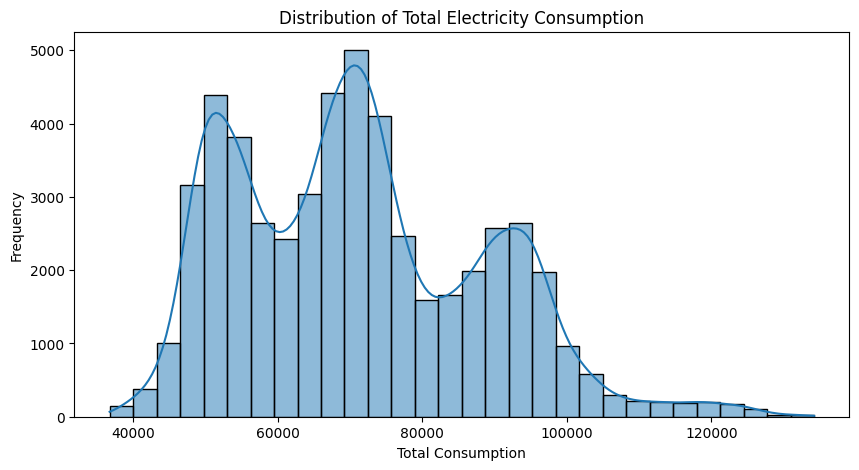

In [ ]:
plt.figure(figsize=(10,5))

sns.histplot(
    data["Total_Consumption"],
    bins=30,
    kde=True
)

plt.title("Distribution of Total Electricity Consumption")
plt.xlabel("Total Consumption")
plt.ylabel("Frequency")

plt.show()

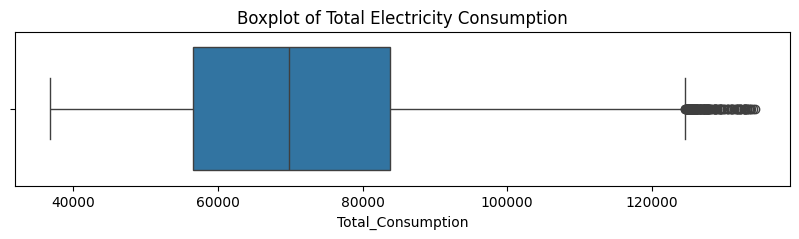

In [ ]:
plt.figure(figsize=(10,2))

sns.boxplot(x=data["Total_Consumption"])

plt.title("Boxplot of Total Electricity Consumption")

plt.show()

In [ ]:
print("Skewness :", data["Total_Consumption"].skew())
print("Kurtosis :", data["Total_Consumption"].kurt())

Skewness : 0.5188535622760272
Kurtosis : -0.2325068669190662


In [ ]:
Q1 = data["Total_Consumption"].quantile(0.25)
Q3 = data["Total_Consumption"].quantile(0.75)

IQR = Q3 - Q1

lower = Q1 - 1.5 * IQR
upper = Q3 + 1.5 * IQR

outliers = data[
    (data["Total_Consumption"] < lower) |
    (data["Total_Consumption"] > upper)
]

print("Lower Limit :", lower)
print("Upper Limit :", upper)
print("Outliers :", len(outliers))
print("Percentage :", round(len(outliers) / len(data) * 100, 2), "%")

Lower Limit : 15623.928135000024
Upper Limit : 124624.31881499998
Outliers : 150
Percentage : 0.29 %


The distribution of the target variable (Total_Consumption) is multimodal and moderately positively skewed (skewness = 0.519). The kurtosis value (-0.233) indicates a slightly flatter distribution than the normal distribution. Using the IQR method, 150 observations (0.29%) were identified as outliers. These observations were retained because they likely correspond to genuine peak electricity demand rather than erroneous measurements, making them important for forecasting.

Calendar Feature Analysis (Time-Based EDA)

Hourly Electricity Consumption

In [ ]:
hourly_consumption = (
    data.groupby("Hour")["Total_Consumption"]
    .mean()
    .reset_index()
)

hourly_consumption


,Hour,Total_Consumption
0,0,68566.531733
1,1,62301.416675
2,2,59003.941184
3,3,56629.313141
4,4,54928.696874
...,...,...
19,19,95645.135118
20,20,98037.110110
21,21,94631.878019
22,22,87882.623668


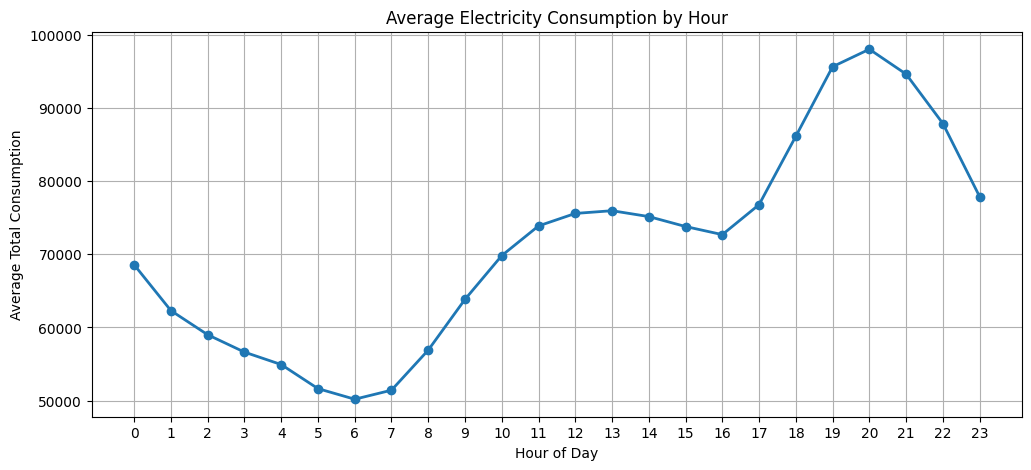

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    hourly_consumption["Hour"],
    hourly_consumption["Total_Consumption"],
    marker="o",
    linewidth=2
)

plt.title("Average Electricity Consumption by Hour")
plt.xlabel("Hour of Day")
plt.ylabel("Average Total Consumption")

plt.xticks(range(24))
plt.grid(True)

plt.show()

Hourly analysis revealed a clear daily consumption pattern. Electricity demand decreases during the night, reaching its minimum around 06:00, and then increases steadily as daily activities begin. The highest average electricity consumption occurs around 20:00, corresponding to peak residential and commercial electricity usage. These results demonstrate that the Hour feature is an important predictor for electricity demand forecasting.

===========================================================================================================
Month-wise Electricity Consumption Analysis

In [ ]:
monthly_consumption = (
    data.groupby("Month")["Total_Consumption"]
    .mean()
    .reset_index()
)

monthly_consumption

,Month,Total_Consumption
0,1,68173.033601
1,2,67108.548882
2,3,66560.788896
3,4,67396.902281
4,5,69994.397979
...,...,...
7,8,85740.300881
8,9,68499.912449
9,10,67560.748669
10,11,65105.067506


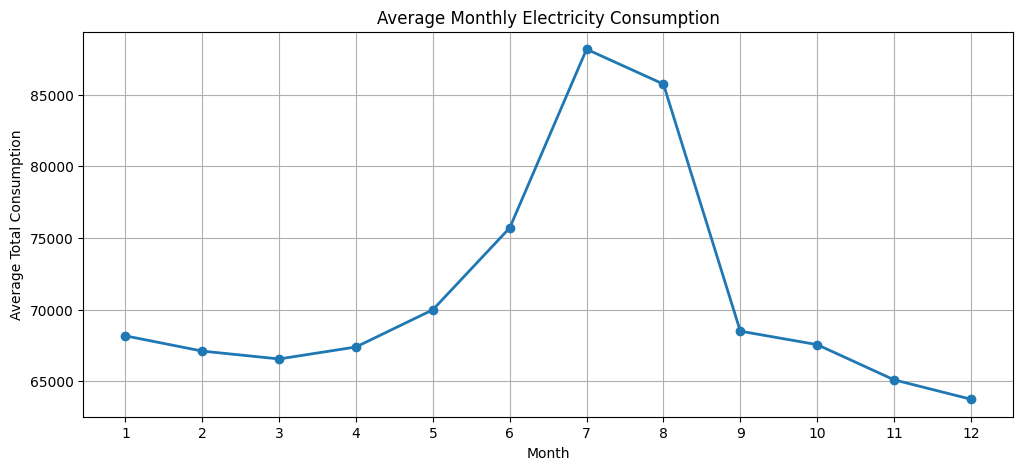

In [ ]:
plt.figure(figsize=(12,5))

plt.plot(
    monthly_consumption["Month"],
    monthly_consumption["Total_Consumption"],
    marker="o",
    linewidth=2
)

plt.title("Average Monthly Electricity Consumption")
plt.xlabel("Month")
plt.ylabel("Average Total Consumption")

plt.xticks(range(1,13))
plt.grid(True)

plt.show()

Monthly analysis revealed a clear seasonal pattern in electricity consumption. Demand increased gradually from April, reached its highest level in July, remained high in August, and then declined toward December, which exhibited the lowest average consumption. This seasonal variation suggests that electricity demand is influenced by recurring annual factors, supporting the use of seasonal forecasting models.

=========================================================================================================

Weekday-wise Electricity Consumption Analysis

In [ ]:
weekday_order = [
    "Monday",
    "Tuesday",
    "Wednesday",
    "Thursday",
    "Friday",
    "Saturday",
    "Sunday"
]

In [ ]:
weekday_consumption = (
    data.groupby("Weekday")["Total_Consumption"]
    .mean()
    .reindex(weekday_order)
    .reset_index()
)

weekday_consumption

,Weekday,Total_Consumption
0,Monday,71704.557279
1,Tuesday,72063.318208
2,Wednesday,72350.516792
3,Thursday,72531.340987
4,Friday,71346.005550
5,Saturday,70850.177537
6,Sunday,67714.284697


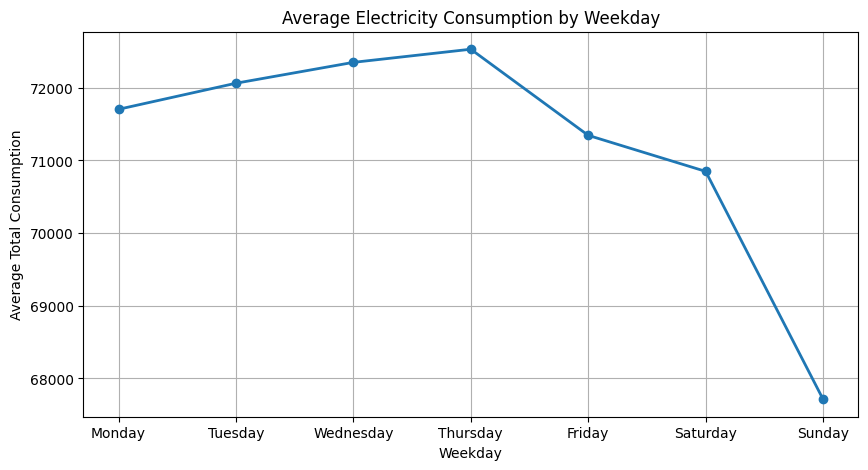

In [ ]:
plt.figure(figsize=(10,5))

plt.plot(
    weekday_consumption["Weekday"],
    weekday_consumption["Total_Consumption"],
    marker="o",
    linewidth=2
)

plt.title("Average Electricity Consumption by Weekday")
plt.xlabel("Weekday")
plt.ylabel("Average Total Consumption")

plt.grid(True)

plt.show()

Weekday-wise analysis indicates a modest weekly pattern in electricity consumption. Demand increases gradually from Monday to Thursday, with Thursday exhibiting the highest average consumption. Electricity usage declines on Friday and Saturday and reaches its lowest level on Sunday, reflecting reduced commercial and industrial activity during the weekend.

============================================================================

Weekend vs Weekday Analysis


In [ ]:
weekend_consumption = (
    data.groupby("Weekend")["Total_Consumption"]
    .mean()
    .reset_index()
)

# Replace numeric labels with text
weekend_consumption["Weekend"] = (
    weekend_consumption["Weekend"]
    .map({0: "Weekday", 1: "Weekend"})
)

weekend_consumption

,Weekend,Total_Consumption
0,Weekday,71999.147763
1,Weekend,69282.231117


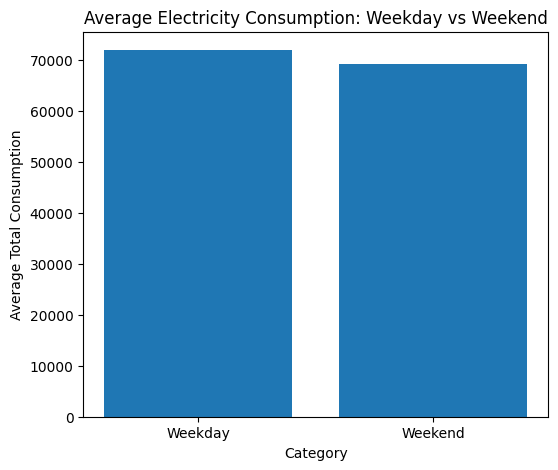

In [ ]:
plt.figure(figsize=(6,5))

plt.bar(
    weekend_consumption["Weekend"],
    weekend_consumption["Total_Consumption"]
)

plt.title("Average Electricity Consumption: Weekday vs Weekend")
plt.xlabel("Category")
plt.ylabel("Average Total Consumption")

plt.show()

The average electricity consumption during weekdays was 71,999 units, compared with 69,282 units during weekends. Weekday demand was approximately 2,717 units (3.9%) higher than weekend demand, reflecting increased commercial and industrial activity on working days. Although the weekend effect is noticeable, it is less pronounced than the hourly and seasonal patterns observed earlier.

=======================================================================

Quarter-wise Consumption

In [ ]:
quarterly_consumption = (
    data.groupby("Quarter")["Total_Consumption"]
    .mean()
    .reset_index()
)

quarterly_consumption

,Quarter,Total_Consumption
0,1,67286.531845
1,2,71021.491601
2,3,80938.334824
3,4,65495.165373


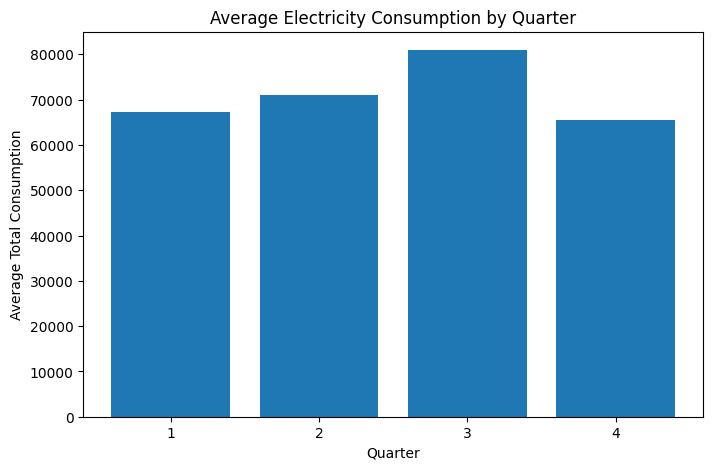

In [ ]:
plt.figure(figsize=(8,5))

plt.bar(
    quarterly_consumption["Quarter"].astype(str),
    quarterly_consumption["Total_Consumption"]
)

plt.title("Average Electricity Consumption by Quarter")
plt.xlabel("Quarter")
plt.ylabel("Average Total Consumption")

plt.show()

Quarter-wise analysis revealed a clear seasonal pattern in electricity consumption. Demand increased from Quarter 1 to Quarter 3, where the highest average electricity consumption was observed. Consumption declined substantially in Quarter 4. These findings further support the presence of seasonality in the dataset.

============================================================================

# Time Series Analysis

Time Plot

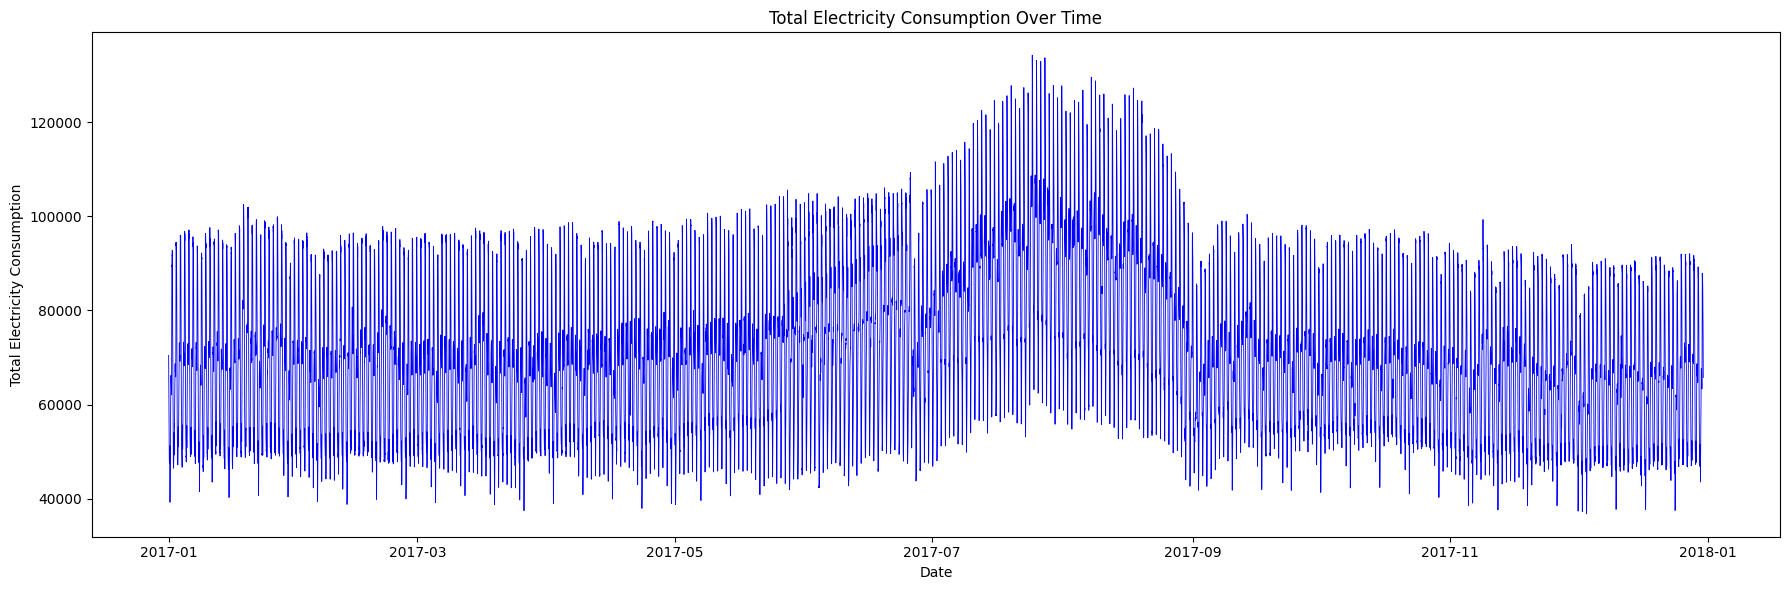

In [ ]:
plt.figure(figsize=(18,6))

plt.plot(
    data.index,
    data["Total_Consumption"],
    color="blue",
    linewidth=0.6
)

plt.title("Total Electricity Consumption Over Time")
plt.xlabel("Date")
plt.ylabel("Total Electricity Consumption")

plt.tight_layout()
plt.show()

The time plot of total electricity consumption reveals clear seasonal fluctuations throughout the year. Electricity demand increases during the middle of the year and declines towards the end of the year, consistent with the monthly and quarterly analyses. The amplitude of fluctuations is larger during July and August, indicating changing variability over time. Since both the mean level and the variability appear to change across the year, the series is visually suggestive of non-stationarity. Formal statistical tests are required to confirm this observation.

================================================================================================

Rolling Mean and Rolling Standard Deviation

In [ ]:
rolling_mean = data["Total_Consumption"].rolling(window=144).mean()
rolling_std = data["Total_Consumption"].rolling(window=144).std()

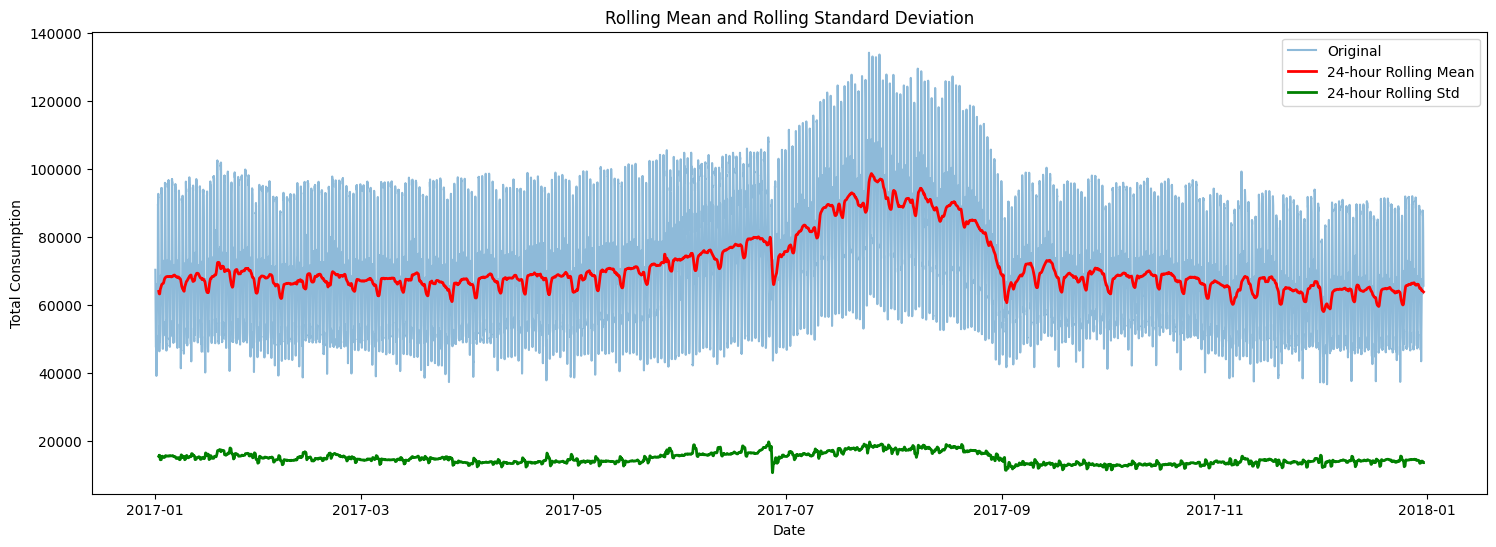

In [ ]:
plt.figure(figsize=(18,6))

plt.plot(
    data.index,
    data["Total_Consumption"],
    label="Original",
    alpha=0.5
)

plt.plot(
    data.index,
    rolling_mean,
    color="red",
    linewidth=2,
    label="24-hour Rolling Mean"
)

plt.plot(
    data.index,
    rolling_std,
    color="green",
    linewidth=2,
    label="24-hour Rolling Std"
)

plt.title("Rolling Mean and Rolling Standard Deviation")
plt.xlabel("Date")
plt.ylabel("Total Consumption")

plt.legend()

plt.show()

A 24-hour rolling window (144 observations) was used to compute the rolling mean and rolling standard deviation of the electricity consumption series. The rolling mean increased during the middle of the year and declined towards the end, indicating that the average level of the series changes over time. Similarly, the rolling standard deviation was higher during July–August and lower during the remaining months, suggesting changes in variability. These observations indicate that the time series is visually non-stationary. Formal stationarity tests were subsequently performed to verify these findings.

**KPSS** (Kwiatkowski–Phillips–Schmidt–Shin) Test

In [ ]:
from statsmodels.tsa.stattools import kpss

kpss_result = kpss(
    data["Total_Consumption"],
    regression="c",      # constant (level stationarity)
    nlags="auto"
)

print("KPSS Statistic :", kpss_result[0])
print("p-value :", kpss_result[1])
print("Lags Used :", kpss_result[2])

print("\nCritical Values")

for key, value in kpss_result[3].items():
    print(f"{key} : {value}")

KPSS Statistic : 5.782766548605797
p-value : 0.01
Lags Used : 133

Critical Values
10% : 0.347
5% : 0.463
2.5% : 0.574
1% : 0.739


/tmp/ipykernel_42968/1575975602.py:3: InterpolationWarning: The test statistic is outside of the range of p-values available in the
look-up table. The actual p-value is smaller than the p-value returned.

  kpss_result = kpss(


The KPSS test yielded a test statistic of 5.7828 with a p-value less than 0.01, leading to the rejection of the null hypothesis of stationarity. the KPSS test and the visual inspection indicated non-stationarity.

Seasonal Decomposition

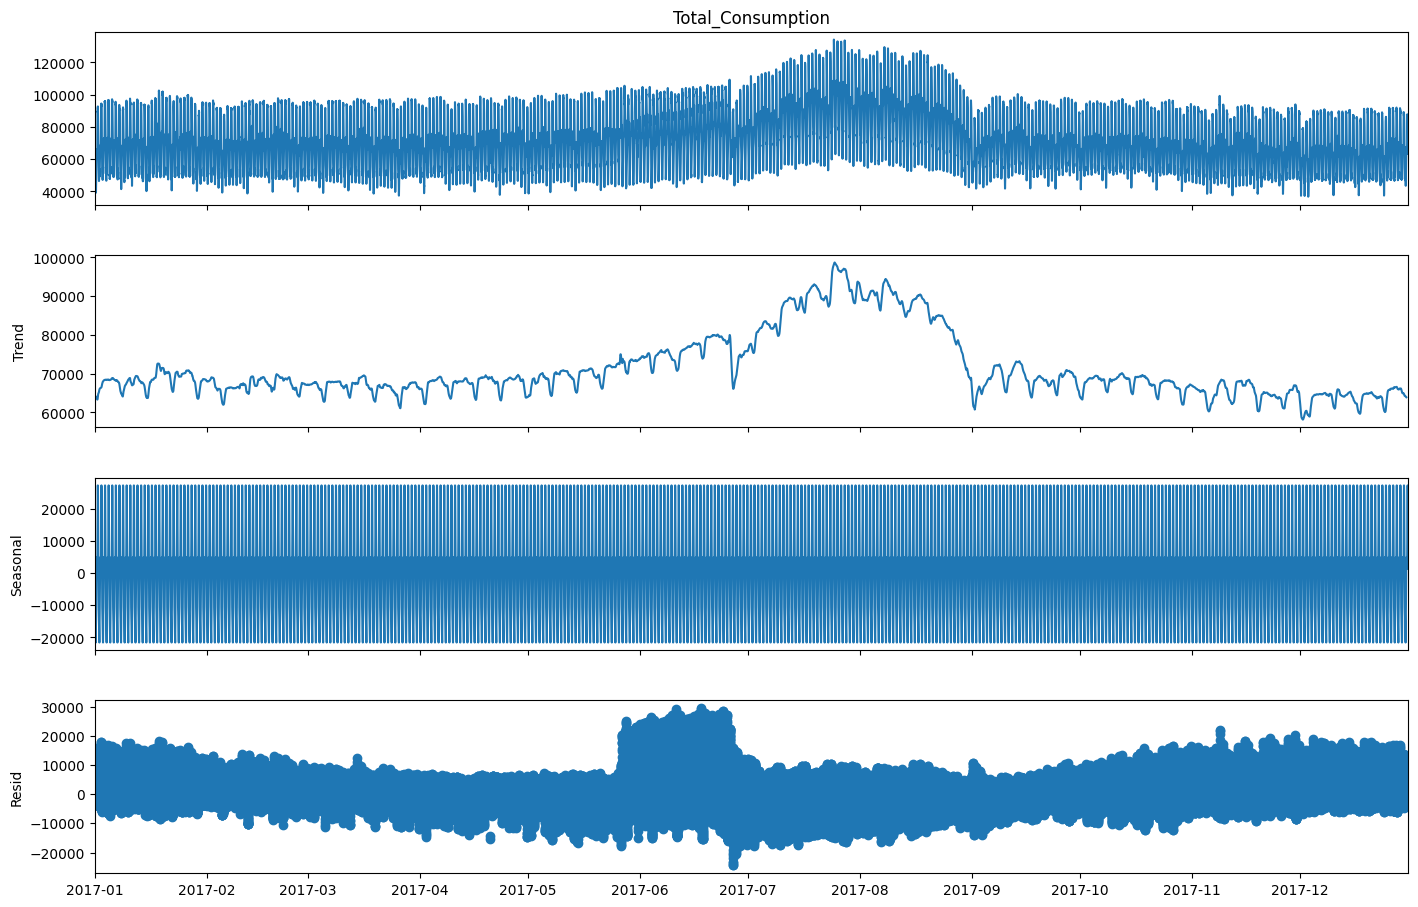

In [ ]:
from statsmodels.tsa.seasonal import seasonal_decompose

decomposition = seasonal_decompose(
    data["Total_Consumption"],
    model="additive",
    period=144
)

fig = decomposition.plot()
fig.set_size_inches(16, 10)

plt.show()

Seasonal decomposition using an additive model and a seasonal period of 144 observations revealed three distinct components. The trend component showed an increase in electricity consumption during the middle of the year followed by a decline towards the end of the year. The seasonal component exhibited a strong and highly regular daily cycle, confirming the presence of pronounced daily seasonality. The residual component fluctuated around zero without an obvious repeating structure, indicating that the decomposition successfully captured the dominant trend and seasonal effects.

Autocorrelation Function (ACF)

<Figure size 1400x600 with 0 Axes>

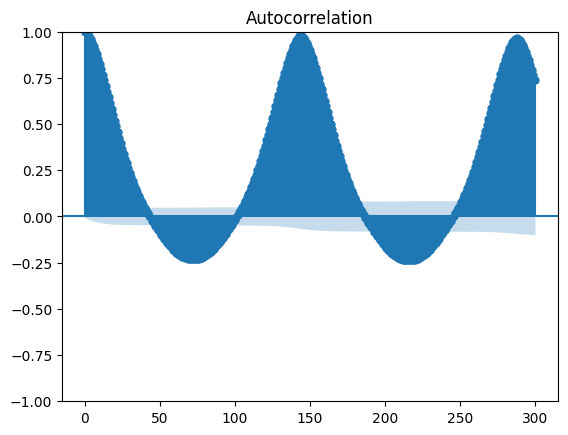

In [ ]:
from statsmodels.graphics.tsaplots import plot_acf

plt.figure(figsize=(14,6))

plot_acf(
    data["Total_Consumption"],
    lags=300,
    alpha=0.05
)

plt.show()

The Autocorrelation Function (ACF) plot revealed strong autocorrelation at small lags, indicating a high dependence between consecutive electricity consumption observations. Pronounced peaks were observed at lags corresponding to approximately 144 observations, confirming the presence of a daily seasonal cycle. The slowly decaying and oscillatory autocorrelation pattern indicates that the series exhibits strong temporal dependence and seasonal structure, supporting the use of a seasonal forecasting model such as SARIMAX.

Partial Autocorrelation Function (PACF)

<Figure size 1400x600 with 0 Axes>

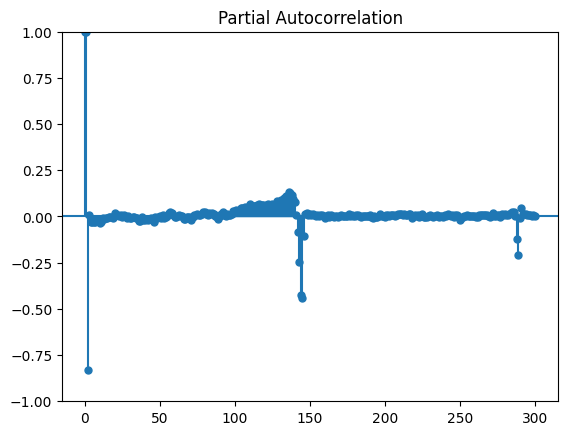

In [ ]:
from statsmodels.graphics.tsaplots import plot_pacf

plt.figure(figsize=(14,6))

plot_pacf(
    data["Total_Consumption"],
    lags=300,
    alpha=0.05,
    method="ywm"
)

plt.show()

The Partial Autocorrelation Function (PACF) plot exhibited a strong spike at lag 1, indicating a direct relationship between consecutive observations. Significant seasonal spikes were also observed around lag 144, confirming the presence of daily seasonal dependence. These findings support the inclusion of both non-seasonal and seasonal autoregressive components in the SARIMAX model. The PACF was used to guide the initial parameter search, while the final model orders were selected using hyperparameter tuning based on information criteria.

# Feature Engineering

Lag Features

In [ ]:
# Create lag features

model_data["Lag_1"] = model_data["Total_Consumption"].shift(1)
model_data["Lag_6"] = model_data["Total_Consumption"].shift(6)
model_data["Lag_18"] = model_data["Total_Consumption"].shift(18)
model_data["Lag_144"] = model_data["Total_Consumption"].shift(144)

print(model_data[
    ["Lag_1", "Lag_6", "Lag_18", "Lag_144"]
].isnull().sum())

model_data.head(10)

NameError: name 'model_data' is not defined

Rolling Features

In [ ]:
# Rolling Mean (1 Hour)
model_data["Rolling_Mean_6"] = (
    model_data["Total_Consumption"]
    .rolling(window=6)
    .mean()
)

# Rolling Standard Deviation (1 Hour)
model_data["Rolling_Std_6"] = (
    model_data["Total_Consumption"]
    .rolling(window=6)
    .std()
)

# Rolling Mean (24 Hours)
model_data["Rolling_Mean_144"] = (
    model_data["Total_Consumption"]
    .rolling(window=144)
    .mean()
)

# Rolling Standard Deviation (24 Hours)
model_data["Rolling_Std_144"] = (
    model_data["Total_Consumption"]
    .rolling(window=144)
    .std()
)

In [ ]:
rolling_features = [
    "Rolling_Mean_6",
    "Rolling_Std_6",
    "Rolling_Mean_144",
    "Rolling_Std_144"
]

print(model_data[rolling_features].isnull().sum())

Rolling_Mean_6        5
Rolling_Std_6         5
Rolling_Mean_144    143
Rolling_Std_144     143
dtype: int64


In [ ]:
model_data.head(10)

,Temperature,Humidity,Wind_Speed,General_Diffuse_Flows,Diffuse_Flows,Zone1,Zone2,Zone3,Total_Consumption,Hour,Day,Month,Weekday,Weekend,Quarter,Lag_1,Lag_6,Lag_18,Lag_144,Rolling_Mean_6,Rolling_Std_6,Rolling_Mean_144,Rolling_Std_144
Datetime,,,,,,,,,,,,,,,,,,,,,,,
2017-01-01 00:00:00,6.559,73.8,0.083,0.051,0.119,34055.69620,16128.87538,20240.96386,70425.53544,0,1,1,Sunday,1,1,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:10:00,6.414,74.5,0.083,0.070,0.085,29814.68354,19375.07599,20131.08434,69320.84387,0,1,1,Sunday,1,1,70425.53544,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:20:00,6.313,74.5,0.080,0.062,0.100,29128.10127,19006.68693,19668.43373,67803.22193,0,1,1,Sunday,1,1,69320.84387,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:30:00,6.121,75.0,0.083,0.091,0.096,28228.86076,18361.09422,18899.27711,65489.23209,0,1,1,Sunday,1,1,67803.22193,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:40:00,5.921,75.7,0.081,0.048,0.085,27335.69620,17872.34043,18442.40964,63650.44627,0,1,1,Sunday,1,1,65489.23209,NaN,NaN,NaN,NaN,NaN,NaN,NaN
2017-01-01 00:50:00,5.853,76.9,0.081,0.059,0.108,26624.81013,17416.41337,18130.12048,62171.34398,0,1,1,Sunday,1,1,63650.44627,NaN,NaN,NaN,66476.770597,3253.951738,NaN,NaN
2017-01-01 01:00:00,5.641,77.7,0.080,0.048,0.096,25998.98734,16993.31307,17945.06024,60937.36065,1,1,1,Sunday,1,1,62171.34398,70425.53544,NaN,NaN,64895.408132,3256.657331,NaN,NaN
2017-01-01 01:10:00,5.496,78.2,0.085,0.055,0.093,25446.07595,16661.39818,17459.27711,59566.75124,1,1,1,Sunday,1,1,60937.36065,69320.84387,NaN,NaN,63269.726027,3032.561090,NaN,NaN
2017-01-01 01:20:00,5.678,78.1,0.081,0.066,0.141,24777.72152,16227.35562,17025.54217,58030.61931,1,1,1,Sunday,1,1,59566.75124,67803.22193,NaN,NaN,61640.958923,2718.841453,NaN,NaN


In [ ]:
model_data = model_data.dropna()

print("Final Dataset Shape :", model_data.shape)

print("\nMissing Values")

print(model_data.isnull().sum())

Final Dataset Shape : (52272, 23)

Missing Values
Temperature              0
Humidity                 0
Wind_Speed               0
General_Diffuse_Flows    0
Diffuse_Flows            0
                        ..
Lag_144                  0
Rolling_Mean_6           0
Rolling_Std_6            0
Rolling_Mean_144         0
Rolling_Std_144          0
Length: 23, dtype: int64


In [ ]:

model_data.info()

<class 'pandas.core.frame.DataFrame'>
DatetimeIndex: 52272 entries, 2017-01-02 00:00:00 to 2017-12-30 23:50:00
Data columns (total 23 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Temperature            52272 non-null  float64
 1   Humidity               52272 non-null  float64
 2   Wind_Speed             52272 non-null  float64
 3   General_Diffuse_Flows  52272 non-null  float64
 4   Diffuse_Flows          52272 non-null  float64
 5   Zone1                  52272 non-null  float64
 6   Zone2                  52272 non-null  float64
 7   Zone3                  52272 non-null  float64
 8   Total_Consumption      52272 non-null  float64
 9   Hour                   52272 non-null  int32  
 10  Day                    52272 non-null  int32  
 11  Month                  52272 non-null  int32  
 12  Weekday                52272 non-null  object 
 13  Weekend                52272 non-null  int64  
 14  Quarter            

In [ ]:
model_data.to_csv(
    "/content/drive/MyDrive/Colab Notebooks/Electric Power Consumption/Data/electricity_model_data.csv",
    index=True
)


In [ ]:
import pandas as pd

model_data = pd.read_csv(
    "/content/drive/MyDrive/Colab Notebooks/Electric Power Consumption/Data/electricity_model_data.csv",
    parse_dates=["Datetime"],
    index_col="Datetime"
)

Chronological Train-Test Split

# Univariate LSTM

In [ ]:
lstm_data = model_data[["Total_Consumption"]]

print(lstm_data.shape)
lstm_data.head()

(52272, 1)


,Total_Consumption
Datetime,
2017-01-02 00:00:00,62667.35846
2017-01-02 00:10:00,61026.11029
2017-01-02 00:20:00,59728.31136
2017-01-02 00:30:00,58343.58633
2017-01-02 00:40:00,57257.22885


Chronological Train-Test Split

In [ ]:
train_size = int(len(lstm_data) * 0.80)

lstm_train = lstm_data.iloc[:train_size]

lstm_test = lstm_data.iloc[train_size:]

print("Train :", lstm_train.shape)
print("Test  :", lstm_test.shape)

Train : (41817, 1)
Test  : (10455, 1)


In [ ]:
from sklearn.preprocessing import MinMaxScaler

scaler = MinMaxScaler(feature_range=(0,1))

train_scaled = scaler.fit_transform(lstm_train)

test_scaled = scaler.transform(lstm_test)

In [ ]:
print(train_scaled.shape)

print(test_scaled.shape)

(41817, 1)
(10455, 1)


In [ ]:
sequence_length = 144
import numpy as np

X_train_lstm = []

y_train_lstm = []

for i in range(sequence_length, len(train_scaled)):

    X_train_lstm.append(
        train_scaled[i-sequence_length:i]
    )

    y_train_lstm.append(
        train_scaled[i]
    )

X_train_lstm = np.array(X_train_lstm)

y_train_lstm = np.array(y_train_lstm)
print(X_train_lstm.shape)

print(y_train_lstm.shape)

(41673, 144, 1)
(41673, 1)


In [ ]:
X_test_lstm = []

y_test_lstm = []

combined = np.concatenate(
    (train_scaled[-sequence_length:], test_scaled),
    axis=0
)

for i in range(sequence_length, len(combined)):

    X_test_lstm.append(
        combined[i-sequence_length:i]
    )

    y_test_lstm.append(
        combined[i]
    )

X_test_lstm = np.array(X_test_lstm)

y_test_lstm = np.array(y_test_lstm)

In [ ]:
print(X_test_lstm.shape)

print(y_test_lstm.shape)

(10455, 144, 1)
(10455, 1)


In [ ]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import LSTM, Dense, Dropout
from tensorflow.keras.callbacks import EarlyStopping

In [ ]:
lstm_model = Sequential([

    LSTM(
        units=64,
        input_shape=(144, 1)
    ),

    Dropout(0.2),

    Dense(32, activation="relu"),

    Dense(1)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [ ]:
lstm_model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
early_stop = EarlyStopping(
    monitor="val_loss",
    patience=5,
    restore_best_weights=True
)

In [ ]:
history = lstm_model.fit(
    X_train_lstm,
    y_train_lstm,
    epochs=30,
    batch_size=64,
    validation_split=0.2,
    callbacks=[early_stop],
    verbose=1
)

Epoch 1/30
 34/521 ━━━━━━━━━━━━━━━━━━━━ 29s 61ms/step - loss: 1.9410e-04 - mae: 0.0101

KeyboardInterrupt: 

In [ ]:
y_pred_scaled = lstm_model.predict(X_test_lstm)

327/327 ━━━━━━━━━━━━━━━━━━━━ 9s 26ms/step


In [ ]:
y_pred = scaler.inverse_transform(y_pred_scaled)

y_actual = scaler.inverse_transform(y_test_lstm)

In [ ]:
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
import numpy as np

mae = mean_absolute_error(y_actual, y_pred)

rmse = np.sqrt(mean_squared_error(y_actual, y_pred))

mape = np.mean(np.abs((y_actual - y_pred) / y_actual)) * 100

r2 = r2_score(y_actual, y_pred)

print("="*40)
print(f"MAE  : {mae:.2f}")
print(f"RMSE : {rmse:.2f}")
print(f"MAPE : {mape:.2f}%")
print(f"R²   : {r2:.4f}")
print("="*40)

MAE  : 529.10
RMSE : 808.95
MAPE : 0.83%
R²   : 0.9967


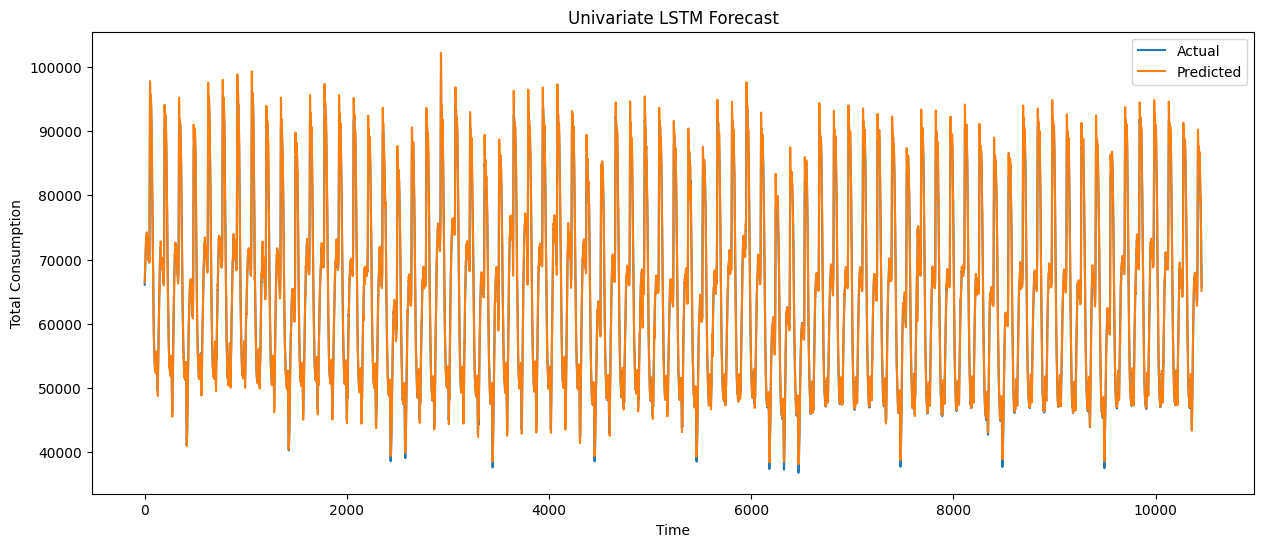

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(15,6))

plt.plot(y_actual, label="Actual")

plt.plot(y_pred, label="Predicted")

plt.title("Univariate LSTM Forecast")

plt.xlabel("Time")

plt.ylabel("Total Consumption")

plt.legend()

plt.show()

In [ ]:
lstm_model.save("/content/drive/MyDrive/Colab Notebooks/Electric Power Consumption/models/univariate_lstm.keras")

In [ ]:
from tensorflow.keras.models import load_model

In [ ]:
lstm_model = load_model("/content/drive/MyDrive/Colab Notebooks/Electric Power Consumption/models/univariate_lstm.keras")

The univariate LSTM model achieved strong forecasting performance with an MAE of 529.10, RMSE of 808.95, MAPE of 0.83%, and an R² score of 0.9967. The model successfully learned the temporal dependencies of electricity consumption using only historical values of the target variable.

In [ ]:
model_2 = Sequential([
    LSTM(64, return_sequences=True, input_shape=(144, 1)),
    Dropout(0.2),

    LSTM(32),
    Dropout(0.2),

    Dense(32, activation="relu"),
    Dense(1)
])

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)
